# Online Retail – Exploratory Data Analysis (EDA)

**Goal:** understand sales, products, countries and customers of a UK online retailer, and segment customers with RFM.

**Dataset:** `Online Retail.xlsx` (UCI Online Retail dataset: invoices from 01 Dec 2010 to 09 Dec 2011).

**Dataset names used in this notebook (each one has ONE meaning):**

| Name | What it is |
|---|---|
| `df_raw` | The original file. Never changed. |
| `df_clean` | `df_raw` after removing exact duplicates and rows with no description. Still contains returns/cancellations. |
| `df_sales` | `df_clean` without the "bad debt" accounting rows, plus a `Revenue` column (returns have negative revenue). |
| `sales` | Real sales only: not cancelled, quantity > 0, price > 0. **Most analysis uses this.** |
| `product_sales` | `sales` without service lines (postage, fees, manual entries). Used for product rankings. |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

sns.set_theme(style='whitegrid')

In [2]:

import os
import zipfile

file_path = '/content/Online Retail.xlsx'

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", os.path.getsize(file_path), "bytes")

    try:
        with zipfile.ZipFile(file_path, 'r') as z:
            print("ZIP test:", z.testzip())
            print("Excel file structure is readable")
    except Exception as e:
        print("File error:", repr(e))


File exists: True
File size: 23715344 bytes
ZIP test: None
Excel file structure is readable


In [3]:

import pandas as pd

file_path = '/content/Online Retail.xlsx'

df_raw = pd.read_excel(
    file_path,
    engine='openpyxl'
)

print("Dataset shape:", df_raw.shape)
display(df_raw.head())



Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [4]:
print("Dataset Shape:", df_raw.shape)

print("\nColumn Names:")
print(df_raw.columns.tolist())

print("\nDataset Information:")
df_raw.info()

print("\nMissing Values:")
display(df_raw.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate Rows:", df_raw.duplicated().sum())

Dataset Shape: (541909, 8)

Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB

Missing Values:


,Missing Values
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0



Duplicate Rows: 5268


In [5]:
import zipfile

file_path = '/content/Online Retail.xlsx'

with zipfile.ZipFile(file_path, 'r') as z:
    print("Excel ZIP valid:", z.testzip())
    print(z.namelist()[:10])

Excel ZIP valid: None
['[Content_Types].xml', '_rels/.rels', 'xl/_rels/workbook.xml.rels', 'xl/workbook.xml', 'xl/sharedStrings.xml', 'xl/theme/theme1.xml', 'xl/styles.xml', 'xl/worksheets/sheet1.xml', 'docProps/core.xml', 'docProps/app.xml']


In [6]:
!pip install -q openpyxl

In [7]:
import pandas as pd

df_raw = pd.read_excel(
    '/content/Online Retail.xlsx',
    engine='openpyxl'
)

print("Dataset shape:", df_raw.shape)
display(df_raw.head())

Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## 1. First look at the data

In [8]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [9]:
print("Date range:", df_raw['InvoiceDate'].min(), "to", df_raw['InvoiceDate'].max())
df_raw.describe()

Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


## 2. Data quality checks (inspect only)

In this section we only **look** at the problems. We do **not** change anything yet.
All cleaning happens in one place, in Section 3.

In [10]:
# Missing values: count and percentage
missing = df_raw.isnull().sum()
missing_percentage = (missing / len(df_raw)) * 100

pd.DataFrame({
    'Missing Values': missing,
    'Missing Percentage': missing_percentage.round(2)
}).sort_values('Missing Percentage', ascending=False)

,Missing Values,Missing Percentage
CustomerID,135080,24.93
Description,1454,0.27
StockCode,0,0.00
InvoiceNo,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
Country,0,0.00


In [11]:
# What do the rows with missing Description / CustomerID look like?
no_desc = df_raw[df_raw['Description'].isnull()]
print("Rows with missing Description:", len(no_desc))
print("  of these, UnitPrice == 0:", (no_desc['UnitPrice'] == 0).sum())
print("  of these, CustomerID also missing:", no_desc['CustomerID'].isnull().sum())

no_cust = df_raw[df_raw['CustomerID'].isnull()]
print("\nRows with missing CustomerID:", len(no_cust),
      f"({len(no_cust) / len(df_raw) * 100:.1f}% of all rows)")

no_desc.head()

Rows with missing Description: 1454
  of these, UnitPrice == 0: 1454
  of these, CustomerID also missing: 1454

Rows with missing CustomerID: 135080 (24.9% of all rows)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
622,536414,22139,NaN,56,2010-12-01 11:52:00,0.0,NaN,United Kingdom
1970,536545,21134,NaN,1,2010-12-01 14:32:00,0.0,NaN,United Kingdom
1971,536546,22145,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1972,536547,37509,NaN,1,2010-12-01 14:33:00,0.0,NaN,United Kingdom
1987,536549,85226A,NaN,1,2010-12-01 14:34:00,0.0,NaN,United Kingdom


In [12]:
# Exact duplicate rows (every column identical)
print("Duplicate rows (extra copies):", df_raw.duplicated().sum())

# Show a few examples so you can see what is being treated as a duplicate
df_raw[df_raw.duplicated(keep=False)].sort_values(['InvoiceNo', 'StockCode']).head(10)

Duplicate rows (extra copies): 5268


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
494,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
517,536409,21866,UNION JACK FLAG LUGGAGE TAG,1,2010-12-01 11:45:00,1.25,17908.0,United Kingdom
485,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
539,536409,22111,SCOTTIE DOG HOT WATER BOTTLE,1,2010-12-01 11:45:00,4.95,17908.0,United Kingdom
489,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
527,536409,22866,HAND WARMER SCOTTY DOG DESIGN,1,2010-12-01 11:45:00,2.10,17908.0,United Kingdom
521,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
537,536409,22900,SET 2 TEA TOWELS I LOVE LONDON,1,2010-12-01 11:45:00,2.95,17908.0,United Kingdom
565,536412,21448,12 DAISY PEGS IN WOOD BOX,2,2010-12-01 11:49:00,1.65,17920.0,United Kingdom
578,536412,21448,12 DAISY PEGS IN WOOD BOX,1,2010-12-01 11:49:00,1.65,17920.0,United Kingdom


In [13]:
# Quantity problems
print("Negative quantities:", (df_raw['Quantity'] < 0).sum())
print("Zero quantities:", (df_raw['Quantity'] == 0).sum())

neg_qty = df_raw[df_raw['Quantity'] < 0]
on_cancel_invoice = neg_qty['InvoiceNo'].astype(str).str.startswith('C')
print("\nNegative-quantity rows on cancellation invoices (InvoiceNo starts with 'C'):", on_cancel_invoice.sum())
print("Negative-quantity rows that are NOT cancellations:", (~on_cancel_invoice).sum())
print("  of these, UnitPrice == 0:", (neg_qty.loc[~on_cancel_invoice, 'UnitPrice'] == 0).sum())

neg_qty.head(10)

Negative quantities: 10624
Zero quantities: 0

Negative-quantity rows on cancellation invoices (InvoiceNo starts with 'C'): 9288
Negative-quantity rows that are NOT cancellations: 1336
  of these, UnitPrice == 0: 1336


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


In [14]:
# Price problems
print("Negative prices:", (df_raw['UnitPrice'] < 0).sum())
print("Zero prices:", (df_raw['UnitPrice'] == 0).sum())

# Negative-price rows: what are they?
df_raw[df_raw['UnitPrice'] < 0]

Negative prices: 2
Zero prices: 2515


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [15]:
# Zero-price rows: free items, samples or data-entry adjustments
zero_price = df_raw[df_raw['UnitPrice'] == 0]

print("Total zero-price rows:", len(zero_price))
print("  with a CustomerID:", zero_price['CustomerID'].notnull().sum())
print("  with negative quantity:", (zero_price['Quantity'] < 0).sum())

print("\nMost common descriptions on zero-price rows:")
print(zero_price['Description'].value_counts(dropna=False).head(15))

Total zero-price rows: 2515
  with a CustomerID: 40
  with negative quantity: 1336

Most common descriptions on zero-price rows:
Description
NaN                              1454
check                             159
?                                  47
damages                            45
damaged                            43
found                              25
sold as set on dotcom              20
adjustment                         16
Damaged                            14
Unsaleable, destroyed.              9
FRENCH BLUE METAL DOOR SIGN 1       9
thrown away                         9
FRENCH BLUE METAL DOOR SIGN 8       8
amazon                              8
Found                               8
Name: count, dtype: int64


In [16]:
# Unusual orders: look at the biggest positive and negative quantities in the ORIGINAL data.
# An order that is placed and then cancelled almost immediately would show up as a matching +/- pair.
cols = ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'UnitPrice', 'CustomerID', 'InvoiceDate']

print("5 largest quantities in df_raw:")
display(df_raw.nlargest(5, 'Quantity')[cols])

print("5 most negative quantities in df_raw:")
display(df_raw.nsmallest(5, 'Quantity')[cols])

5 largest quantities in df_raw:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,InvoiceDate
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,16446.0,2011-12-09 09:15:00
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346.0,2011-01-18 10:01:00
502122,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,0.00,13256.0,2011-11-25 15:57:00
74614,542504,37413,NaN,5568,0.00,NaN,2011-01-28 12:03:00
421632,573008,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,4800,0.21,12901.0,2011-10-27 12:26:00


5 most negative quantities in df_raw:


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,InvoiceDate
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,16446.0,2011-12-09 09:27:00
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,12346.0,2011-01-18 10:17:00
225529,556690,23005,printing smudges/thrown away,-9600,0.00,NaN,2011-06-14 10:37:00
225530,556691,23005,printing smudges/thrown away,-9600,0.00,NaN,2011-06-14 10:37:00
4287,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,0.03,15838.0,2010-12-02 14:23:00


## 3. Data cleaning (one pipeline, run once)

| Step | What we do | Why |
|---|---|---|
| 1 | Remove exact duplicate rows | Same invoice, product, quantity, price and timestamp repeated = most likely a double entry. |
| 2 | Remove rows with no `Description` | These rows have no product name and (see Section 2) are zero-price stock adjustments. They cannot be analysed as sales. |
| 3 | Fix data types | `InvoiceNo`/`StockCode` as text (they mix numbers and letters), `CustomerID` as whole number. |
| 4 | Remove "Adjust bad debt" rows | These are accounting entries (large negative prices), not product sales. |
| 5 | Remove one fully reversed order (the order **and** its cancellation) | A huge order cancelled minutes later with the same quantity has zero net effect. Keeping only the original would fake ~77,000 of revenue. (Evidence: Section 2, "Unusual orders".) |
| 5b | Add `Revenue = Quantity x UnitPrice` | Returns get negative revenue. |
| 6 | **Keep** cancellations in `df_sales` | They are real events (returns). We study them separately in Section 4. |
| 7 | `sales` = not cancelled, `Quantity > 0`, `UnitPrice > 0` | Zero-price rows add no revenue, and negative quantities are returns/damages, not sales. |
| 8 | **Keep** rows with no `CustomerID` in `sales` | They are real purchases (revenue counts). They are only excluded from customer-level analysis (repeat customers, RFM). |

In [17]:
# ==========================================
# DATA CLEANING PIPELINE  (run this cell only once, from top to bottom)
# ==========================================

# 1. Start from the original data
df_clean = df_raw.copy()
rows_raw = len(df_clean)

# 2. Remove exact duplicate rows
n_duplicates = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates().copy()

# 3. Remove rows with missing Description
n_missing_desc = df_clean['Description'].isna().sum()
df_clean = df_clean.dropna(subset=['Description']).copy()

# 4. Standardize data types
df_clean['InvoiceNo'] = df_clean['InvoiceNo'].astype(str)
df_clean['StockCode'] = df_clean['StockCode'].astype(str)
df_clean['Description'] = df_clean['Description'].astype(str).str.strip().str.upper()
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'], errors='coerce')
df_clean['CustomerID'] = df_clean['CustomerID'].astype('Int64')   # whole numbers, keeps missing values

# 5. Remove rows where the date could not be read (we expect 0)
n_bad_dates = df_clean['InvoiceDate'].isna().sum()
df_clean = df_clean.dropna(subset=['InvoiceDate']).copy()

# 6. Remove bad-debt accounting adjustments
bad_debt_mask = df_clean['Description'].str.contains('ADJUST BAD DEBT', na=False)
n_bad_debt = bad_debt_mask.sum()
df_sales = df_clean.loc[~bad_debt_mask].copy()

# 6b. Remove ONE fully reversed order (both the order and its cancellation).
#     Section 2 ("Unusual orders") shows a huge order that was cancelled ~16 minutes later
#     with exactly the same quantity, so its net effect is zero. If we keep only the original
#     order it looks like 77,000+ of revenue that never really happened.
#     To undo this decision, set reversed_invoices = [] and re-run from here.
reversed_invoices = ['541431', 'C541433']
reversed_mask = df_sales['InvoiceNo'].isin(reversed_invoices)
n_reversed = reversed_mask.sum()
print("Rows removed as fully reversed order:", n_reversed)
display(df_sales.loc[reversed_mask, ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'UnitPrice', 'CustomerID', 'InvoiceDate']])
df_sales = df_sales.loc[~reversed_mask].copy()

# 7. Revenue (returns/cancellations stay in df_sales with negative revenue)
df_sales['Revenue'] = df_sales['Quantity'] * df_sales['UnitPrice']
df_sales['IsCancellation'] = df_sales['InvoiceNo'].str.startswith('C')

# 8. Real sales only
n_cancellations = df_sales['IsCancellation'].sum()
sales = df_sales.loc[
    (~df_sales['IsCancellation']) &
    (df_sales['Quantity'] > 0) &
    (df_sales['UnitPrice'] > 0)
].copy()
n_other_invalid = len(df_sales) - n_cancellations - len(sales)

print("Cleaning finished.")
print("df_raw:", df_raw.shape, "| df_clean:", df_clean.shape,
      "| df_sales:", df_sales.shape, "| sales:", sales.shape)

Rows removed as fully reversed order: 2


,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,InvoiceDate
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,12346,2011-01-18 10:01:00
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,12346,2011-01-18 10:17:00


Cleaning finished.
df_raw: (541909, 8) | df_clean: (535187, 8) | df_sales: (535182, 10) | sales: (524876, 10)


In [18]:
# Row reconciliation: every removed row must be accounted for
steps = pd.DataFrame({
    'Step': [
        'Original rows (df_raw)',
        'Exact duplicates removed',
        'Missing Description removed',
        'Unreadable dates removed',
        'Bad-debt adjustments removed',
        'Fully reversed order removed (order + its cancellation)',
        'Cancellation invoices (kept in df_sales, not in sales)',
        'Other non-sales rows (Quantity <= 0 or UnitPrice <= 0)',
        'Final sales rows (sales)'
    ],
    'Rows': [
        rows_raw, n_duplicates, n_missing_desc, n_bad_dates,
        n_bad_debt, n_reversed, n_cancellations, n_other_invalid, len(sales)
    ]
})
print(steps.to_string(index=False))

# Safety check: the numbers must add up exactly
assert rows_raw - n_duplicates - n_missing_desc - n_bad_dates - n_bad_debt - n_reversed \
       - n_cancellations - n_other_invalid == len(sales), "Row counts do not add up!"
print("\nCheck passed: all rows are accounted for.")
print("Remaining duplicate rows in sales:", sales.duplicated().sum())
print("Rows in sales with missing CustomerID (kept):", sales['CustomerID'].isna().sum())

                                                   Step   Rows
                                 Original rows (df_raw) 541909
                               Exact duplicates removed   5268
                            Missing Description removed   1454
                               Unreadable dates removed      0
                           Bad-debt adjustments removed      3
Fully reversed order removed (order + its cancellation)      2
 Cancellation invoices (kept in df_sales, not in sales)   9250
 Other non-sales rows (Quantity <= 0 or UnitPrice <= 0)   1056
                               Final sales rows (sales) 524876

Check passed: all rows are accounted for.
Remaining duplicate rows in sales: 0
Rows in sales with missing CustomerID (kept): 132185


## 4. Returns and cancellations

`sales` contains **gross** sales (cancellations are not in it). Here we measure how big the returns are, so we do not ignore them.

In [19]:
returns = df_sales[df_sales['IsCancellation']]

gross_revenue = sales['Revenue'].sum()
returns_value = returns['Revenue'].sum()        # negative number
net_revenue = gross_revenue + returns_value

print(f"Gross sales revenue:      {gross_revenue:>15,.2f}")
print(f"Cancelled / returned:     {returns_value:>15,.2f}")
print(f"Net revenue:              {net_revenue:>15,.2f}")
print(f"Return rate (by value):   {-returns_value / gross_revenue * 100:>14.2f} %")
print("Cancellation line items:", len(returns), "| cancellation invoices:", returns['InvoiceNo'].nunique())

Gross sales revenue:        10,553,865.14
Cancelled / returned:         -816,796.13
Net revenue:                 9,737,069.01
Return rate (by value):             7.74 %
Cancellation line items: 9250 | cancellation invoices: 3835


## 5. Prepare the `sales` dataset for analysis

* Add date columns (year, month, year-month).
* Some `StockCode` values are **not products** (postage, fees, manual entries). They are real money, so they stay in `sales` for revenue totals, but they should not appear in "top products". First we look at which non-standard codes exist in your data:

In [20]:
# Normal product codes start with 5 digits (e.g. 85123A). Show everything else:
non_standard = sales[~sales['StockCode'].str.match(r'^\d{5}')]

(non_standard.groupby(['StockCode', 'Description'])
    .agg(Rows=('Revenue', 'size'), Revenue=('Revenue', 'sum'))
    .sort_values('Revenue', ascending=False)
    .head(20)
    .round(2))

,,Rows,Revenue
StockCode,Description,,
DOT,DOTCOM POSTAGE,706,206248.77
POST,POSTAGE,1126,78101.88
M,MANUAL,316,77750.27
AMAZONFEE,AMAZON FEE,2,13761.09
C2,CARRIAGE,141,7051.00
gift_0001_30,DOTCOMGIFTSHOP GIFT VOUCHER £30.00,7,175.53
gift_0001_50,DOTCOMGIFTSHOP GIFT VOUCHER £50.00,4,167.56
gift_0001_20,DOTCOMGIFTSHOP GIFT VOUCHER £20.00,9,167.05
BANK CHARGES,BANK CHARGES,12,165.00


In [21]:
# Date features
sales['YearMonth'] = sales['InvoiceDate'].dt.to_period('M')
sales['Month'] = sales['InvoiceDate'].dt.month
sales['Year'] = sales['InvoiceDate'].dt.year

# Service lines that are not products. Edit this list if the table above shows others.
non_product_codes = ['POST', 'D', 'M', 'm', 'DOT', 'CRUK', 'C2', 'S', 'B',
                     'AMAZONFEE', 'BANK CHARGES', 'PADS']

sales['IsProduct'] = ~sales['StockCode'].isin(non_product_codes)
product_sales = sales[sales['IsProduct']].copy()

print("Service/non-product rows kept in `sales` for revenue totals:", (~sales['IsProduct']).sum())
print("Revenue from those rows:", round(sales.loc[~sales['IsProduct'], 'Revenue'].sum(), 2))
print("product_sales rows (used for product rankings):", len(product_sales))

Service/non-product rows kept in `sales` for revenue totals: 2309
Revenue from those rows: 383143.61
product_sales rows (used for product rankings): 522567


## 6. Sales analysis & visualization

In [22]:
# Key numbers (all from `sales`, i.e. gross sales)
no_cust_rows = sales['CustomerID'].isna()

print(f"Total line items (transactions): {len(sales):,}")
print(f"Total invoices:                  {sales['InvoiceNo'].nunique():,}")
print(f"Total revenue:                   {sales['Revenue'].sum():,.2f}")
print(f"Unique products (StockCodes):    {product_sales['StockCode'].nunique():,}")
print(f"Unique countries:                {sales['Country'].nunique():,}")
print(f"Unique identified customers:     {sales['CustomerID'].nunique():,}")
print(f"Rows without CustomerID:         {no_cust_rows.sum():,} "
      f"({no_cust_rows.mean() * 100:.1f}% of rows, "
      f"{sales.loc[no_cust_rows, 'Revenue'].sum() / sales['Revenue'].sum() * 100:.1f}% of revenue)")

Total line items (transactions): 524,876
Total invoices:                  19,958
Total revenue:                   10,553,865.14
Unique products (StockCodes):    3,912
Unique countries:                38
Unique identified customers:     4,337
Rows without CustomerID:         132,185 (25.2% of rows, 16.5% of revenue)


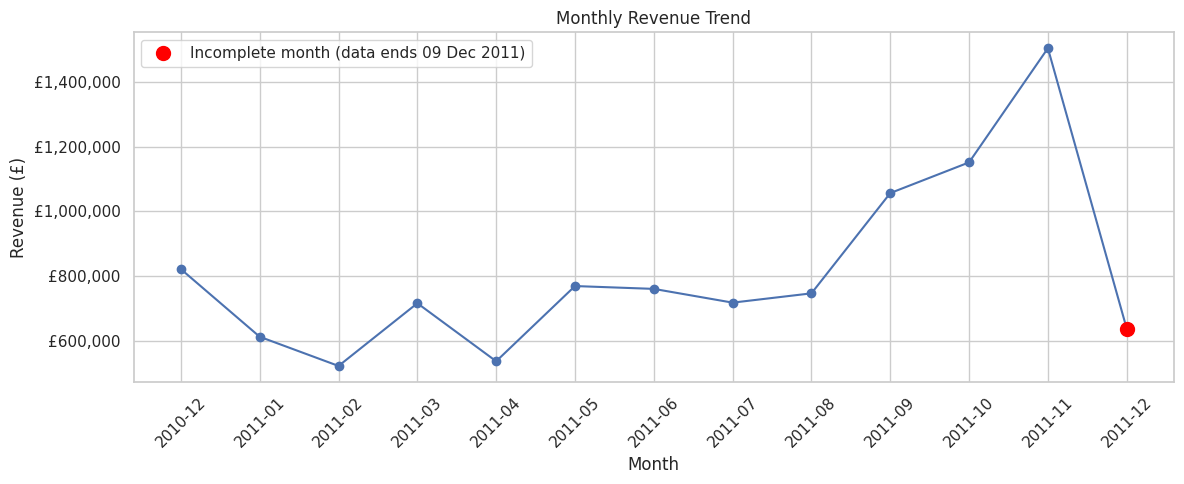

In [23]:
# Monthly revenue (computed once, reused later)
monthly_revenue = sales.groupby('YearMonth')['Revenue'].sum()

# The dataset ends in the middle of a month -> the last month is incomplete
last_date = sales['InvoiceDate'].max()
is_partial_last = last_date.day < last_date.days_in_month

x = monthly_revenue.index.astype(str)
y = monthly_revenue.values

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(x, y, marker='o')

if is_partial_last:
    ax.plot(x[-1], y[-1], marker='o', color='red', markersize=10, linestyle='none',
            label=f"Incomplete month (data ends {last_date:%d %b %Y})")
    ax.legend()

ax.set_title('Monthly Revenue Trend')
ax.set_xlabel('Month')
ax.set_ylabel('Revenue (£)')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('£{x:,.0f}'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

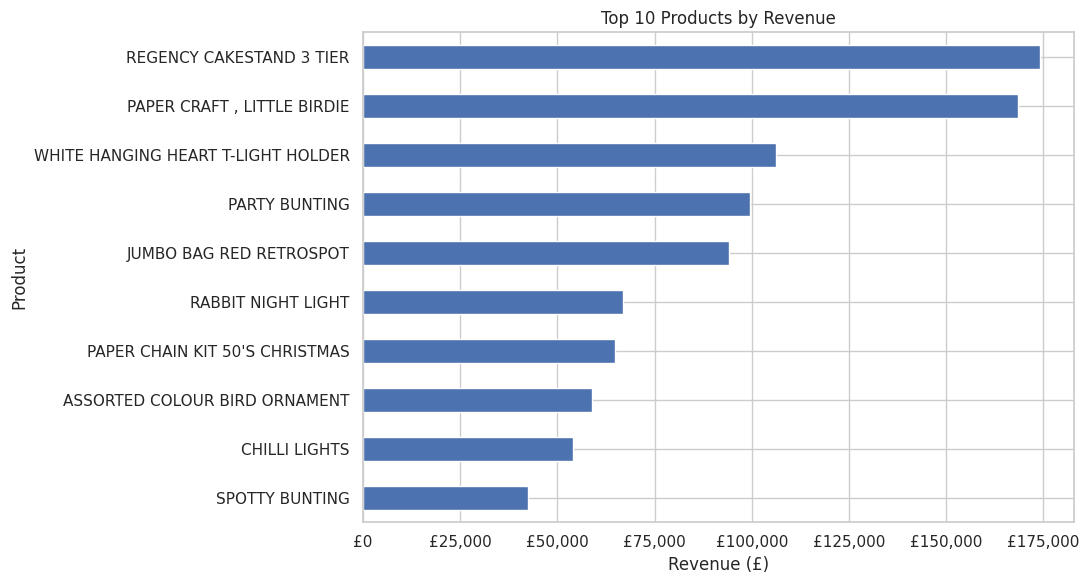

In [24]:
# Top 10 products by revenue (real products only)
top_products = (
    product_sales.groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

ax = top_products.sort_values().plot(kind='barh', figsize=(11, 6))

ax.set_title('Top 10 Products by Revenue')
ax.set_xlabel('Revenue (£)')
ax.set_ylabel('Product')
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('£{x:,.0f}'))
plt.tight_layout()
plt.show()

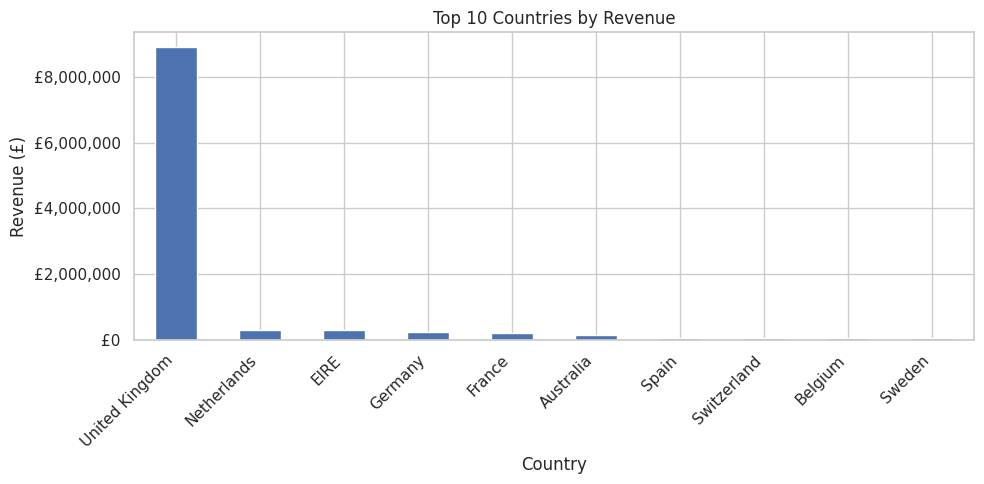

In [25]:
# Country-wise revenue
country_sales = (
    sales.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

ax = country_sales.plot(kind='bar', figsize=(10, 5))

ax.set_title('Top 10 Countries by Revenue')
ax.set_xlabel('Country')
ax.set_ylabel('Revenue (£)')
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter('£{x:,.0f}'))
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 7. Customer analysis + product performance

In [26]:
# Customer-wise total spending (only rows that have a CustomerID)
customer_sales = (
    sales.dropna(subset=['CustomerID'])
    .groupby('CustomerID')
    .agg(
        Total_Spending=('Revenue', 'sum'),
        Total_Orders=('InvoiceNo', 'nunique'),
        Total_Items=('Quantity', 'sum')
    )
    .sort_values('Total_Spending', ascending=False)
)

customer_sales.head(10).round(2)

,Total_Spending,Total_Orders,Total_Items
CustomerID,,,
14646,280206.02,73,196915
18102,259657.30,60,64124
17450,194390.79,46,69973
16446,168472.50,2,80997
14911,143711.17,201,80240
12415,124914.53,21,77374
14156,117210.08,55,57768
17511,91062.38,31,64549
16029,80850.84,63,40108


In [27]:
# Average Order Value (AOV) = total revenue / number of invoices
order_revenue = sales.groupby('InvoiceNo')['Revenue'].sum()

aov = order_revenue.mean()
median_order_value = order_revenue.median()

print("Number of invoices:", len(order_revenue))
print("Average Order Value (mean):", round(aov, 2))
print("Median order value:", round(median_order_value, 2),
      "(lower than the mean because a few very large orders pull the average up)")

Number of invoices: 19958
Average Order Value (mean): 528.8
Median order value: 303.3 (lower than the mean because a few very large orders pull the average up)


In [28]:
# Repeat customers = customers with more than 1 invoice
customer_orders = (
    sales.dropna(subset=['CustomerID'])
    .groupby('CustomerID')['InvoiceNo']
    .nunique()
)

total_customers = len(customer_orders)
repeat_customers = (customer_orders > 1).sum()
repeat_percentage = repeat_customers / total_customers * 100

print("Total customers:", total_customers)
print("Repeat customers:", repeat_customers)
print("Repeat customer percentage:", round(repeat_percentage, 2), "%")

Total customers: 4337
Repeat customers: 2845
Repeat customer percentage: 65.6 %


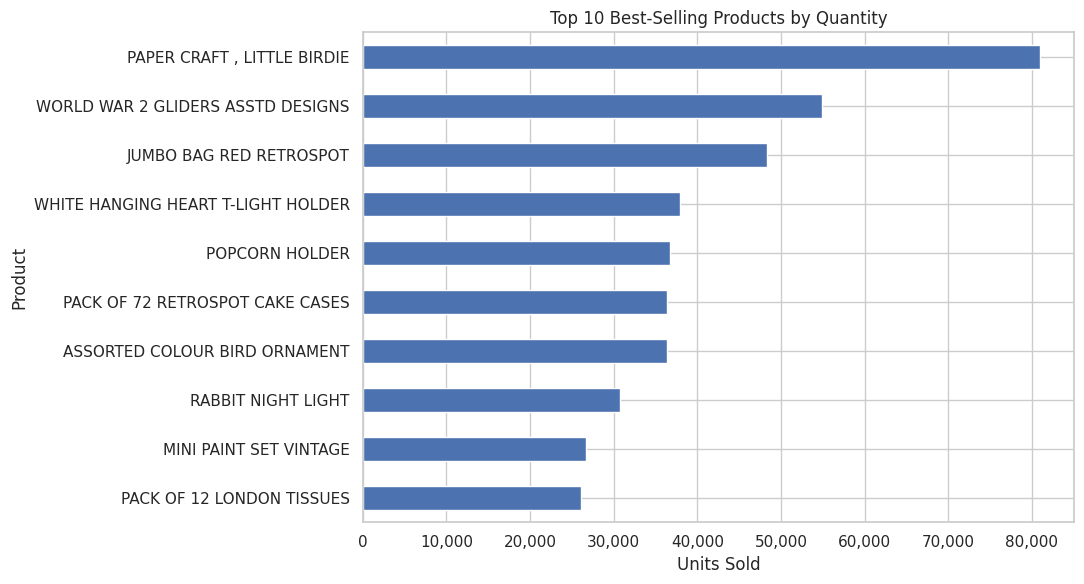

In [29]:
# Best-selling products by quantity (real products only)
top_quantity = (
    product_sales.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

ax = top_quantity.sort_values().plot(kind='barh', figsize=(11, 6))

ax.set_title('Top 10 Best-Selling Products by Quantity')
ax.set_xlabel('Units Sold')
ax.set_ylabel('Product')
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter('{x:,.0f}'))
plt.tight_layout()
plt.show()

In [30]:
# Revenue vs quantity comparison (real products only)
product_analysis = product_sales.groupby('Description').agg(
    Total_Revenue=('Revenue', 'sum'),
    Total_Quantity=('Quantity', 'sum')
)

# Average price actually paid per unit = total revenue / total units
product_analysis['Average_Unit_Price'] = (
    product_analysis['Total_Revenue'] / product_analysis['Total_Quantity']
)

product_analysis = product_analysis.sort_values('Total_Revenue', ascending=False)

product_analysis.head(10).round(2)

,Total_Revenue,Total_Quantity,Average_Unit_Price
Description,,,
REGENCY CAKESTAND 3 TIER,174156.54,13851,12.57
"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995,2.08
WHITE HANGING HEART T-LIGHT HOLDER,106236.72,37872,2.81
PARTY BUNTING,99445.23,18283,5.44
JUMBO BAG RED RETROSPOT,94159.81,48371,1.95
RABBIT NIGHT LIGHT,66870.03,30739,2.18
PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329,3.36
ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362,1.62
CHILLI LIGHTS,54096.36,10302,5.25


## 8. RFM customer segmentation

* **Recency** – days since the customer's last purchase (lower is better)
* **Frequency** – number of invoices
* **Monetary** – total spending

Only customers with a `CustomerID` can be scored.

In [31]:
# RFM dataset: real sales from identified customers
rfm_data = sales.dropna(subset=['CustomerID']).copy()
print(rfm_data.shape)

(392691, 14)


In [32]:
# Reference date = one day after the last invoice in the data
snapshot_date = rfm_data['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = rfm_data.groupby('CustomerID').agg(
    LastPurchase=('InvoiceDate', 'max'),
    Frequency=('InvoiceNo', 'nunique'),
    Monetary=('Revenue', 'sum')
)
rfm['Recency'] = (snapshot_date - rfm['LastPurchase']).dt.days
rfm = rfm[['Recency', 'Frequency', 'Monetary']]

rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12347,2,7,4310.00
12348,75,4,1797.24
12349,19,1,1757.55
12350,310,1,334.40
12352,36,8,2506.04


In [33]:
# Scores from 1 (worst) to 4 (best)

# Recency: most recent customers get 4.  rank(method='first') avoids duplicate bin edges.
rfm['R_Score'] = pd.qcut(rfm['Recency'].rank(method='first'), 4, labels=[4, 3, 2, 1]).astype(int)

# Frequency: fixed, easy-to-read groups (many customers share the same order count,
# so quartiles would split identical customers into different scores)
#   1 order -> 1 | 2 orders -> 2 | 3-4 orders -> 3 | 5+ orders -> 4
rfm['F_Score'] = pd.cut(rfm['Frequency'], bins=[0, 1, 2, 4, np.inf], labels=[1, 2, 3, 4]).astype(int)

# Monetary: highest spenders get 4
rfm['M_Score'] = pd.qcut(rfm['Monetary'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)

rfm['RFM_Score'] = (
    rfm['R_Score'].astype(str)
    + rfm['F_Score'].astype(str)
    + rfm['M_Score'].astype(str)
)

rfm.head(10)

,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
CustomerID,,,,,,,
12347,2,7,4310.00,4,4,4,444
12348,75,4,1797.24,2,3,4,234
12349,19,1,1757.55,3,1,4,314
12350,310,1,334.40,1,1,2,112
12352,36,8,2506.04,3,4,4,344
12353,204,1,89.00,1,1,1,111
12354,232,1,1079.40,1,1,3,113
12355,214,1,459.40,1,1,2,112
12356,23,3,2811.43,3,3,4,334


In [34]:
# Divide customers into segments (defined once)
def segment_customer(row):

    R = row['R_Score']
    F = row['F_Score']
    M = row['M_Score']

    # Recently active, frequent and high-spending customers
    if R >= 3 and F >= 3 and M >= 3:
        return 'Best Customers'

    # Frequent customers with recent purchases
    elif R >= 3 and F >= 3:
        return 'Loyal Customers'

    # Recent purchase, but only one order so far
    elif R >= 3 and F == 1:
        return 'Recent One-Time Buyers'

    # Previously active customers who may need attention
    elif R <= 2 and F >= 2:
        return 'At-Risk / Inactive Customers'

    # Remaining customers
    else:
        return 'Other Customers'


rfm['Segment'] = rfm.apply(segment_customer, axis=1)

print(rfm['Segment'].value_counts())

Segment
Other Customers                 1503
Best Customers                  1297
At-Risk / Inactive Customers    1034
Recent One-Time Buyers           358
Loyal Customers                  145
Name: count, dtype: int64


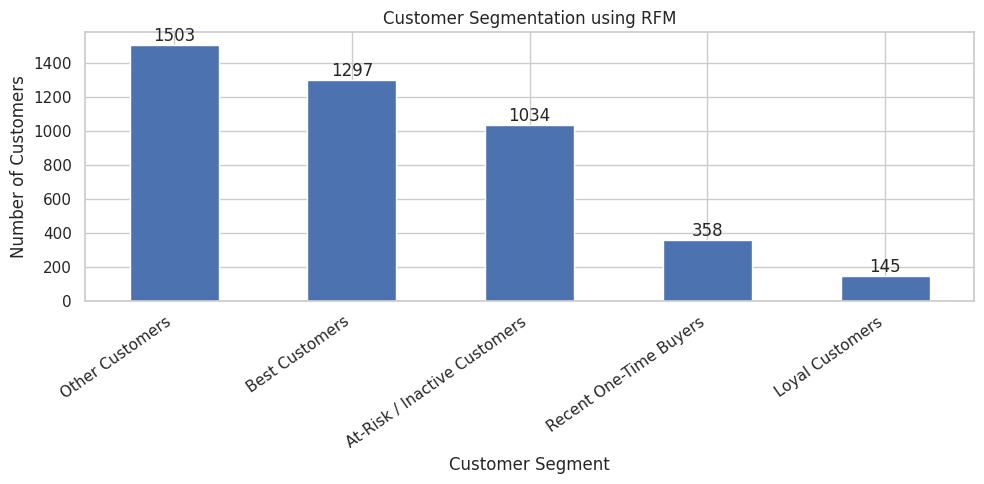

In [35]:
# Segment visualization
segment_counts = rfm['Segment'].value_counts()

ax = segment_counts.plot(kind='bar', figsize=(10, 5))
ax.bar_label(ax.containers[0])

ax.set_title('Customer Segmentation using RFM')
ax.set_xlabel('Customer Segment')
ax.set_ylabel('Number of Customers')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.show()

In [36]:
# How does each segment perform?
segment_summary = rfm.groupby('Segment').agg(
    Customers=('Recency', 'size'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Total_Monetary=('Monetary', 'sum')
).round(2)

segment_summary.sort_values('Total_Monetary', ascending=False)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Monetary
Segment,,,,,
Best Customers,1297,16.91,9.48,4982.00,6461648.87
At-Risk / Inactive Customers,1034,129.80,3.38,1287.67,1331455.58
Other Customers,1503,154.50,1.25,547.77,823295.66
Recent One-Time Buyers,358,26.73,1.00,340.94,122055.88
Loyal Customers,145,21.82,3.47,493.58,71569.30


In [37]:
# Validation: do the segments behave the way their names say?
validation = rfm.groupby('Segment').agg(
    Avg_R_Score=('R_Score', 'mean'),
    Avg_F_Score=('F_Score', 'mean'),
    Avg_M_Score=('M_Score', 'mean'),
    Min_Recency=('Recency', 'min'),
    Max_Recency=('Recency', 'max')
).round(2)

# Consistency checks with earlier sections
print("Customers in RFM table:", len(rfm), "| customers in Section 7:", total_customers)
assert len(rfm) == total_customers, "RFM customer count does not match repeat-customer analysis!"
assert abs(rfm['Monetary'].sum() - sales.dropna(subset=['CustomerID'])['Revenue'].sum()) < 0.01
print("Check passed: RFM totals match the sales data.")

validation

Customers in RFM table: 4337 | customers in Section 7: 4337
Check passed: RFM totals match the sales data.


,Avg_R_Score,Avg_F_Score,Avg_M_Score,Min_Recency,Max_Recency
Segment,,,,,
At-Risk / Inactive Customers,1.64,2.73,2.67,51,373
Best Customers,3.59,3.71,3.64,1,51
Loyal Customers,3.45,3.09,1.87,1,51
Other Customers,1.87,1.25,1.70,1,374
Recent One-Time Buyers,3.27,1.00,1.50,1,51


## 9. Business insights tables

In [38]:
# Monthly revenue and month-over-month (MoM) growth
monthly_summary = monthly_revenue.to_frame(name='Revenue')
monthly_summary['MoM_Growth_%'] = monthly_summary['Revenue'].pct_change() * 100

# The last month is incomplete, so its growth is not comparable
monthly_summary['Complete_Month'] = True
if is_partial_last:
    monthly_summary.iloc[-1, monthly_summary.columns.get_loc('Complete_Month')] = False

monthly_summary.round(2)

,Revenue,MoM_Growth_%,Complete_Month
YearMonth,,,
2010-12,821452.73,NaN,True
2011-01,612628.01,-25.42,True
2011-02,522545.56,-14.70,True
2011-03,716215.26,37.06,True
2011-04,536968.49,-25.03,True
2011-05,769296.61,43.27,True
2011-06,760547.01,-1.14,True
2011-07,718076.12,-5.58,True
2011-08,746779.32,4.00,True


In [39]:
# Country-wise sales contribution
country_revenue = (
    sales.groupby('Country')['Revenue']
    .sum()
    .sort_values(ascending=False)
)

country_summary = pd.DataFrame({
    'Revenue': country_revenue,
    'Share_Percentage': country_revenue / country_revenue.sum() * 100
})

country_summary.head(10).round(2)

,Revenue,Share_Percentage
Country,,
United Kingdom,8913498.43,84.46
Netherlands,285446.34,2.70
EIRE,283140.52,2.68
Germany,228678.40,2.17
France,209625.37,1.99
Australia,138453.81,1.31
Spain,61558.56,0.58
Switzerland,57067.60,0.54
Belgium,41196.34,0.39


## 10. Key findings

*(Write these yourself after running the notebook, using the numbers you see. Suggested points:)*

1. Total gross revenue, returns and net revenue (Section 4).
2. Which months were strongest, and why the last month looks low (incomplete data).
3. Which products and countries bring the most revenue (and how dominant the UK is).
4. Repeat-customer percentage and AOV.
5. Which RFM segment brings the most revenue, and one action you would take for the At-Risk segment.

In [40]:
#Revenue insights

# STEP 1: Revenue Analysis

gross_revenue = sales['Revenue'].sum()

returns_value = df_sales.loc[
    df_sales['IsCancellation'], 'Revenue'
].sum()

net_revenue = gross_revenue + returns_value

return_rate = abs(returns_value) / gross_revenue * 100

print(f"Gross Revenue: £{gross_revenue:,.2f}")
print(f"Returns/Cancellations: £{abs(returns_value):,.2f}")
print(f"Net Revenue: £{net_revenue:,.2f}")
print(f"Return Rate by Value: {return_rate:.2f}%")


Gross Revenue: £10,553,865.14
Returns/Cancellations: £816,796.13
Net Revenue: £9,737,069.01
Return Rate by Value: 7.74%


In [41]:

# STEP 2: Monthly Revenue Analysis

monthly_summary = monthly_revenue.sort_values(
    ascending=False
)

print("Top 3 Revenue Months:")
display(monthly_summary.head(3).to_frame("Revenue"))

print("\nLast month in dataset:")
print("Last invoice date:", sales['InvoiceDate'].max())

print("\nMonthly Revenue:")
display(monthly_revenue.to_frame("Revenue"))


Top 3 Revenue Months:


,Revenue
YearMonth,
2011-11,1503866.780
2011-10,1151263.730
2011-09,1056435.192



Last month in dataset:
Last invoice date: 2011-12-09 12:50:00

Monthly Revenue:


,Revenue
YearMonth,
2010-12,821452.730
2011-01,612628.010
2011-02,522545.560
2011-03,716215.260
2011-04,536968.491
2011-05,769296.610
2011-06,760547.010
2011-07,718076.121
2011-08,746779.320


,Revenue,Quantity
Description,,
REGENCY CAKESTAND 3 TIER,174156.54,13851
"PAPER CRAFT , LITTLE BIRDIE",168469.60,80995
WHITE HANGING HEART T-LIGHT HOLDER,106236.72,37872
PARTY BUNTING,99445.23,18283
JUMBO BAG RED RETROSPOT,94159.81,48371
RABBIT NIGHT LIGHT,66870.03,30739
PAPER CHAIN KIT 50'S CHRISTMAS,64875.59,19329
ASSORTED COLOUR BIRD ORNAMENT,58927.62,36362
CHILLI LIGHTS,54096.36,10302


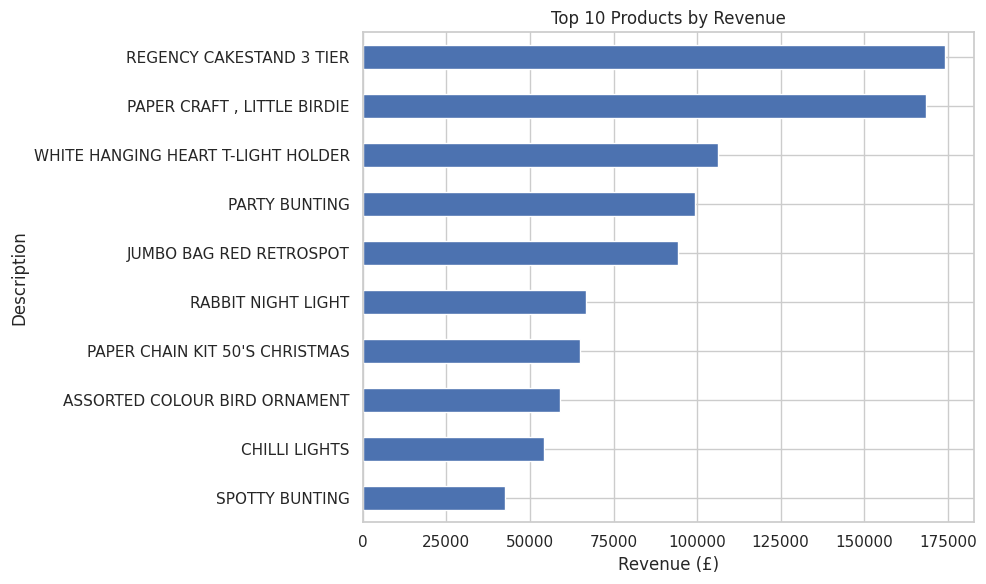

In [42]:

# STEP 3: Top 10 Products by Revenue

top_products = (
    product_sales.groupby('Description')
    .agg(
        Revenue=('Revenue', 'sum'),
        Quantity=('Quantity', 'sum')
    )
    .sort_values('Revenue', ascending=False)
    .head(10)
)

display(top_products)

top_products['Revenue'].sort_values().plot(
    kind='barh',
    figsize=(10, 6),
    title='Top 10 Products by Revenue'
)

plt.xlabel('Revenue (£)')
plt.tight_layout()
plt.show()


In [43]:

# STEP 4: Country-wise Revenue

country_summary = (
    sales.groupby('Country')
    .agg(Revenue=('Revenue', 'sum'))
    .sort_values('Revenue', ascending=False)
)

country_summary['Share_Percentage'] = (
    country_summary['Revenue']
    / country_summary['Revenue'].sum()
    * 100
)

display(country_summary.head(10).round(2))

print(
    "\nUK Revenue Share:",
    round(country_summary.loc[
        'United Kingdom', 'Share_Percentage'
    ], 2),
    "%"
)


,Revenue,Share_Percentage
Country,,
United Kingdom,8913498.43,84.46
Netherlands,285446.34,2.70
EIRE,283140.52,2.68
Germany,228678.40,2.17
France,209625.37,1.99
Australia,138453.81,1.31
Spain,61558.56,0.58
Switzerland,57067.60,0.54
Belgium,41196.34,0.39



UK Revenue Share: 84.46 %


In [44]:

# STEP 5: Customer Behaviour Analysis

identified_sales = sales.dropna(subset=['CustomerID'])

customer_orders = identified_sales.groupby(
    'CustomerID'
)['InvoiceNo'].nunique()

total_customers = customer_orders.size

repeat_customers = (customer_orders > 1).sum()

repeat_percentage = (
    repeat_customers / total_customers * 100
)

order_revenue = sales.groupby('InvoiceNo')['Revenue'].sum()

aov = order_revenue.mean()
median_order_value = order_revenue.median()

print("Identified Customers:", total_customers)
print("Repeat Customers:", repeat_customers)
print(f"Repeat Customer Percentage: {repeat_percentage:.2f}%")
print(f"Average Order Value: £{aov:.2f}")
print(f"Median Order Value: £{median_order_value:.2f}")


Identified Customers: 4337
Repeat Customers: 2845
Repeat Customer Percentage: 65.60%
Average Order Value: £528.80
Median Order Value: £303.30


,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Total_Monetary
Segment,,,,,
Best Customers,1297,16.91,9.48,4982.00,6461648.87
At-Risk / Inactive Customers,1034,129.80,3.38,1287.67,1331455.58
Other Customers,1503,154.50,1.25,547.77,823295.66
Recent One-Time Buyers,358,26.73,1.00,340.94,122055.88
Loyal Customers,145,21.82,3.47,493.58,71569.30


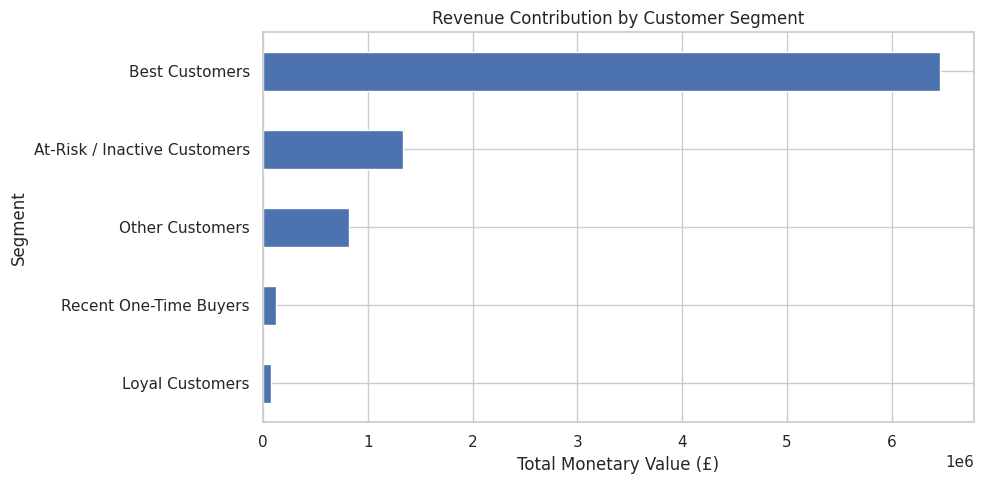

In [45]:

# STEP 6: RFM Segment Analysis

segment_summary = rfm.groupby('Segment').agg(
    Customers=('Recency', 'size'),
    Avg_Recency=('Recency', 'mean'),
    Avg_Frequency=('Frequency', 'mean'),
    Avg_Monetary=('Monetary', 'mean'),
    Total_Monetary=('Monetary', 'sum')
).sort_values('Total_Monetary', ascending=False)

display(segment_summary.round(2))

segment_summary['Total_Monetary'].sort_values().plot(
    kind='barh',
    figsize=(10, 5),
    title='Revenue Contribution by Customer Segment'
)

plt.xlabel('Total Monetary Value (£)')
plt.tight_layout()
plt.show()


In [46]:

# STEP 7: Final Business Insights

best_month = monthly_revenue.idxmax()
best_month_revenue = monthly_revenue.max()

best_segment = segment_summary['Total_Monetary'].idxmax()
best_segment_revenue = segment_summary.loc[
    best_segment, 'Total_Monetary'
]

at_risk_count = int(
    segment_summary.loc[
        'At-Risk / Inactive Customers', 'Customers'
    ]
)

uk_share = country_summary.loc[
    'United Kingdom', 'Share_Percentage'
]

print("========== FINAL BUSINESS INSIGHTS ==========")

print(f"1. Net Revenue: £{net_revenue:,.2f}")

print(
    f"2. Highest Revenue Month: {best_month} "
    f"(£{best_month_revenue:,.2f})"
)

print(f"3. UK Revenue Contribution: {uk_share:.2f}%")

print(f"4. Repeat Customer Rate: {repeat_percentage:.2f}%")

print(
    f"5. Top Customer Segment: {best_segment} "
    f"(£{best_segment_revenue:,.2f})"
)

print(f"6. At-Risk Customers: {at_risk_count}")

print("\nRecommended actions:")
print("- Investigate returns and cancellations.")
print("- Analyse seasonal sales patterns.")
print("- Test customer retention campaigns.")
print("- Evaluate international growth opportunities.")


========== FINAL BUSINESS INSIGHTS ==========
1. Net Revenue: £9,737,069.01
2. Highest Revenue Month: 2011-11 (£1,503,866.78)
3. UK Revenue Contribution: 84.46%
4. Repeat Customer Rate: 65.60%
5. Top Customer Segment: Best Customers (£6,461,648.87)
6. At-Risk Customers: 1034

Recommended actions:
- Investigate returns and cancellations.
- Analyse seasonal sales patterns.
- Test customer retention campaigns.
- Evaluate international growth opportunities.


In [47]:

# STEP 8: Business Recommendations

print("BUSINESS RECOMMENDATIONS\n")

print("1. Customer Retention")
print("Best Customers ke liye loyalty rewards aur exclusive offers test karein.")

print("\n2. Customer Reactivation")
print("At-Risk customers ke liye targeted campaigns chalayein.")

print("\n3. Product Strategy")
print("High-revenue products ki demand aur stock availability monitor karein.")

print("\n4. International Growth")
print("UK ke alawa other countries mein demand aur delivery costs analyse karein.")

print("\n5. Returns Management")
print("High-return products aur cancellation patterns investigate karein.")


BUSINESS RECOMMENDATIONS

1. Customer Retention
Best Customers ke liye loyalty rewards aur exclusive offers test karein.

2. Customer Reactivation
At-Risk customers ke liye targeted campaigns chalayein.

3. Product Strategy
High-revenue products ki demand aur stock availability monitor karein.

4. International Growth
UK ke alawa other countries mein demand aur delivery costs analyse karein.

5. Returns Management
High-return products aur cancellation patterns investigate karein.


In [48]:

# STEP 9: Project Limitations

limitations = [
    "December 2011 data is incomplete.",
    "Some transactions have missing CustomerID values.",
    "Revenue analysis does not include product costs or profit margins.",
    "Historical data may not represent current customer behaviour.",
    "RFM segments depend on the scoring rules used."
]

print("PROJECT LIMITATIONS\n")

for i, limitation in enumerate(limitations, start=1):
    print(f"{i}. {limitation}")


PROJECT LIMITATIONS

1. December 2011 data is incomplete.
2. Some transactions have missing CustomerID values.
3. Revenue analysis does not include product costs or profit margins.
4. Historical data may not represent current customer behaviour.
5. RFM segments depend on the scoring rules used.


## 11. Final Conclusion

This project analysed the Online Retail dataset using Python, Pandas, NumPy and Matplotlib.

The analysis examined revenue trends, product performance, country-wise sales, customer purchasing behaviour and RFM-based customer segmentation.

The findings showed that the United Kingdom contributed the largest share of revenue, November 2011 recorded the highest monthly revenue, and the Best Customers segment contributed the largest monetary value.

The analysis also identified opportunities to investigate returns, improve customer retention and evaluate international market expansion.

These findings can support business decisions, although profitability and the effectiveness of marketing campaigns require further analysis.

Overall, this project demonstrates how Exploratory Data Analysis can transform raw retail transaction data into meaningful business insights.

In [49]:

# STEP 11: Final Validation

print("========== PROJECT VALIDATION ==========")

print("Dataset loaded:", not df_raw.empty)
print("Cleaned sales available:", not sales.empty)
print("RFM analysis available:", not rfm.empty)
print("Monthly revenue calculated:", not monthly_revenue.empty)
print("Country analysis available:", not country_summary.empty)

print("\nDataset date range:")
print(sales['InvoiceDate'].min(), "to", sales['InvoiceDate'].max())

print("\nMissing CustomerID in sales:", sales['CustomerID'].isna().sum())

print("\nValidation completed.")


========== PROJECT VALIDATION ==========
Dataset loaded: True
Cleaned sales available: True
RFM analysis available: True
Monthly revenue calculated: True
Country analysis available: True

Dataset date range:
2010-12-01 08:26:00 to 2011-12-09 12:50:00

Missing CustomerID in sales: 132185

Validation completed.
